In [1]:
!pip install pandapower

     ---------------------------------------- 0.0/13.2 MB ? eta -:--:--
      --------------------------------------- 0.3/13.2 MB ? eta -:--:--
     --- ------------------------------------ 1.0/13.2 MB 3.9 MB/s eta 0:00:04
     ----- ---------------------------------- 1.8/13.2 MB 4.0 MB/s eta 0:00:03
     ------- -------------------------------- 2.6/13.2 MB 3.8 MB/s eta 0:00:03
     --------- ------------------------------ 3.1/13.2 MB 3.8 MB/s eta 0:00:03
     --------- ------------------------------ 3.1/13.2 MB 3.8 MB/s eta 0:00:03
     --------- ------------------------------ 3.1/13.2 MB 3.8 MB/s eta 0:00:03
     ----------- ---------------------------- 3.7/13.2 MB 2.4 MB/s eta 0:00:05
     -------------- ------------------------- 4.7/13.2 MB 2.7 MB/s eta 0:00:04
     --------------- ------------------------ 5.2/13.2 MB 2.8 MB/s eta 0:00:03
     --------------- ------------------------ 5.2/13.2 MB 2.8 MB/s eta 0:00:03
     --------------- ------------------------ 5.2/13.2 MB 2.8 MB/s

explo project 

Line Parameters After Adding DGs (Before BESS):
    from_bus  to_bus  length_km  r_ohm_per_km  x_ohm_per_km  total_r  total_x
0          0       1        1.0        0.0922        0.0470   0.0922   0.0470
1          1       2        1.0        0.4930        0.2511   0.4930   0.2511
2          2       3        1.0        0.3660        0.1864   0.3660   0.1864
3          3       4        1.0        0.3811        0.1941   0.3811   0.1941
4          4       5        1.0        0.8190        0.7070   0.8190   0.7070
5          5       6        1.0        0.1872        0.6188   0.1872   0.6188
6          6       7        1.0        0.7114        0.2351   0.7114   0.2351
7          7       8        1.0        1.0300        0.7400   1.0300   0.7400
8          8       9        1.0        1.0440        0.7400   1.0440   0.7400
9          9      10        1.0        0.1966        0.0650   0.1966   0.0650
10        10      11        1.0        0.3744        0.1238   0.3744   0.1238
11        11    

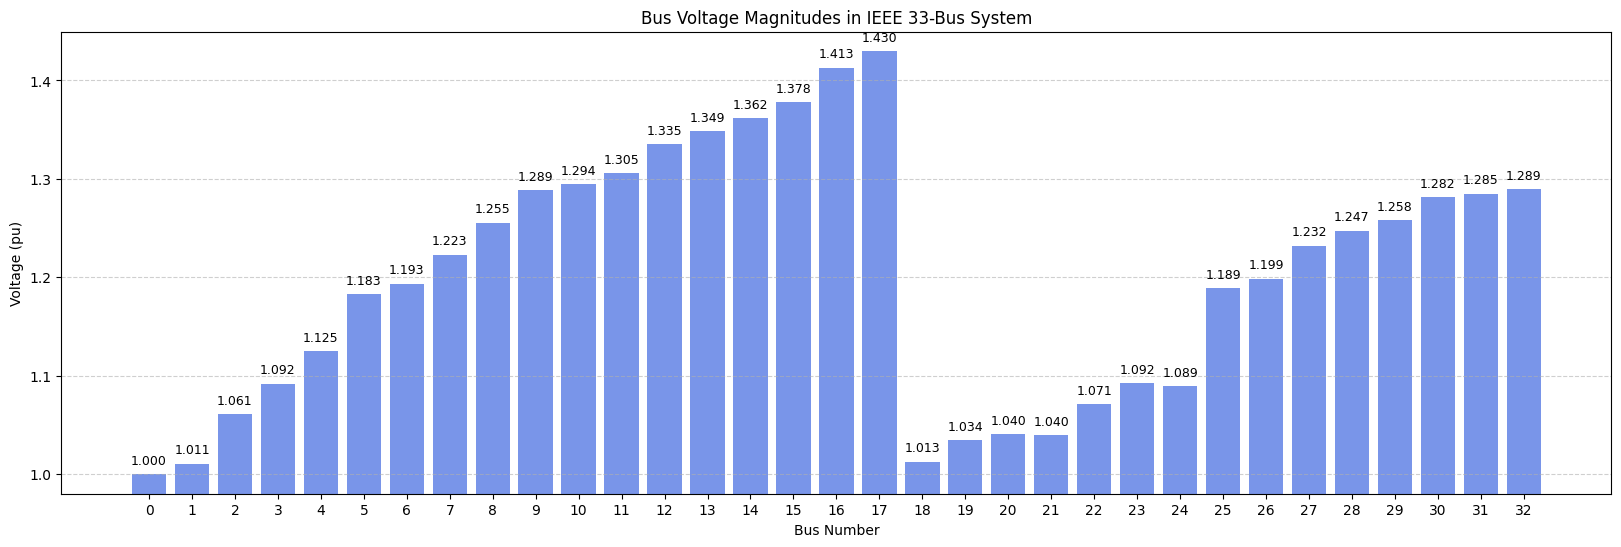

Optimal BESS Bus: 17
Best Cost for BESS : 2016.5416002639895


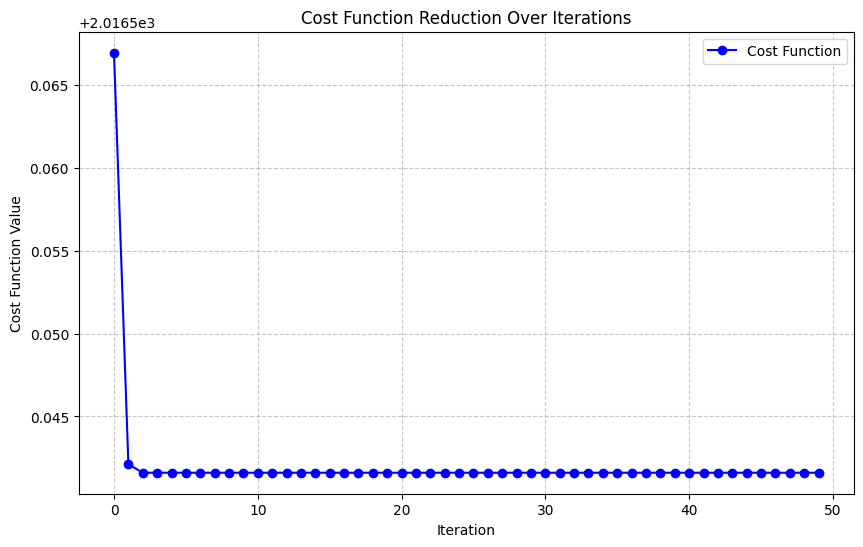

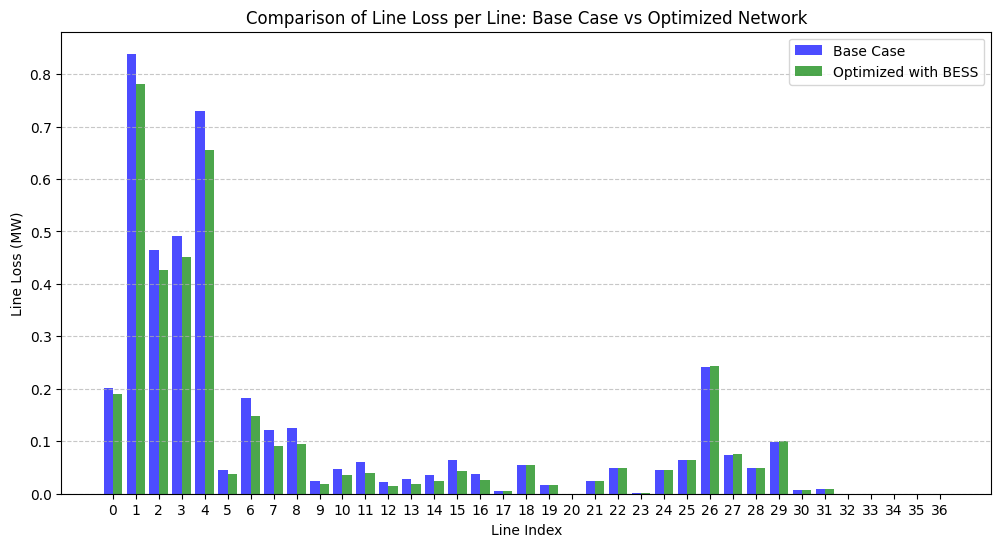

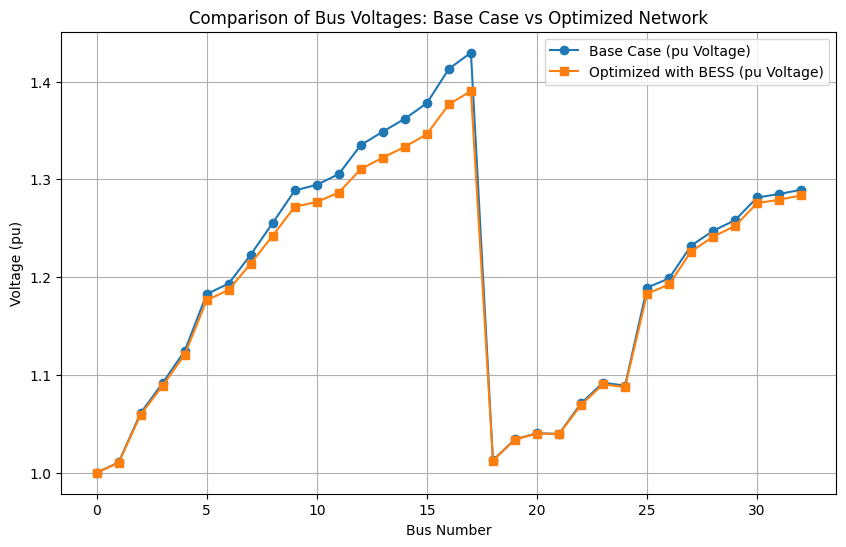

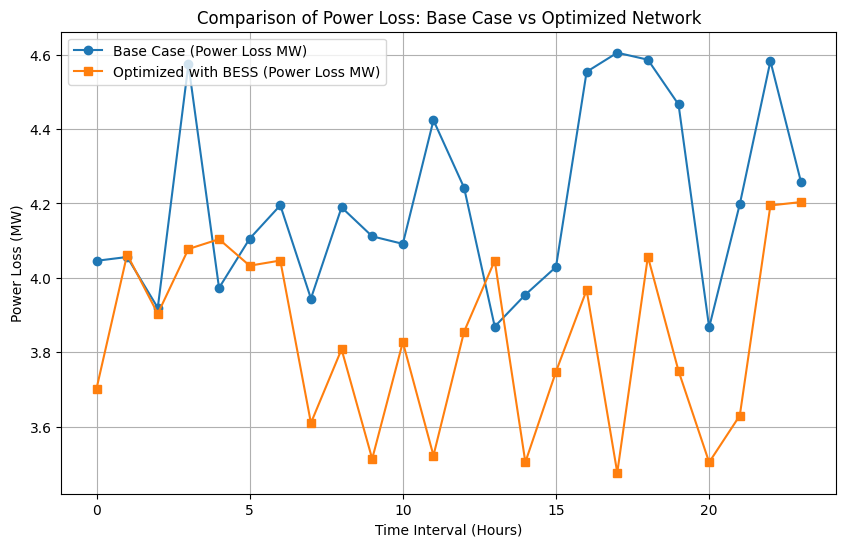

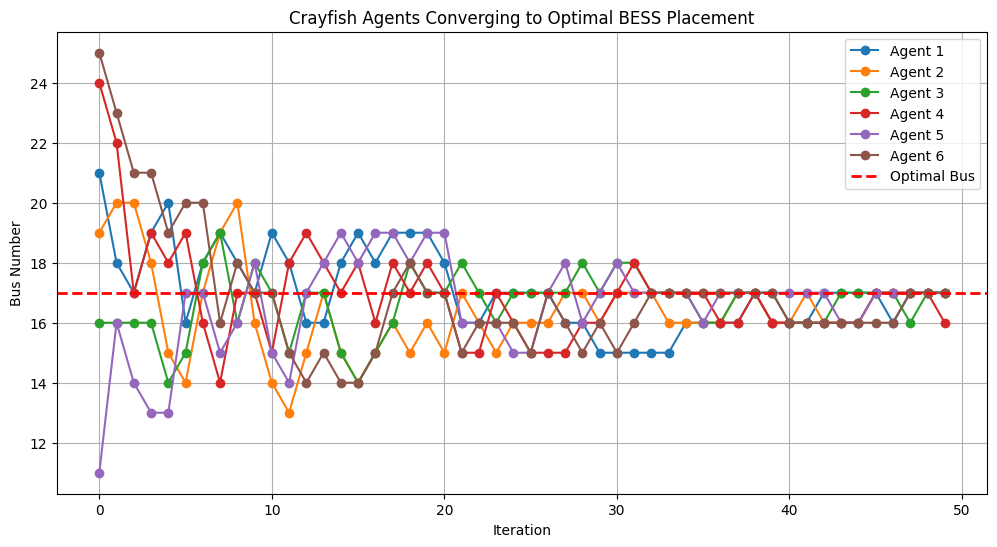

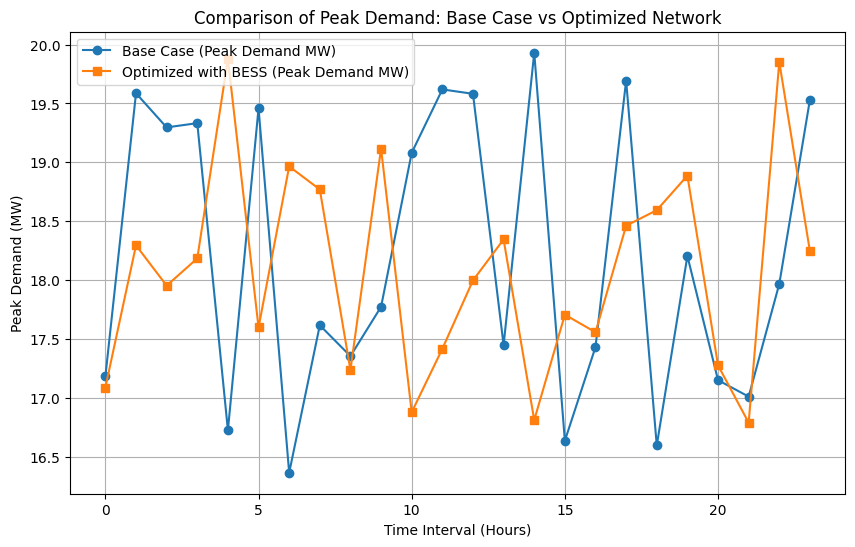

In [2]:
import pandapower as pp
import pandapower.networks as pn
import numpy as np
import random
import copy
import matplotlib.pyplot as plt
from scipy.fft import fft, ifft

# Load IEEE 33-Bus Network
net = pn.case33bw()

# Add PV, DG, and Wind Turbine
pv_dg = [4, 7, 11, 20, 27, 30, 32]
wind_dg = [17, 23]

for bus in pv_dg:
    pp.create_sgen(net, bus=bus, p_mw=2.8, q_mvar=0)

for bus in wind_dg:
    pp.create_sgen(net, bus=bus, p_mw=3.56, q_mvar=2.19)

pp.create_gen(net, bus=0, p_mw=2.0)

# Run Base Load Flow
pp.runpp(net, numba=False)

#input data table##################################

# Extract Line Parameters
line_data_dg = net.line[['from_bus', 'to_bus', 'length_km', 'r_ohm_per_km', 'x_ohm_per_km']].copy()
line_data_dg['total_r'] = line_data_dg['length_km'] * line_data_dg['r_ohm_per_km']
line_data_dg['total_x'] = line_data_dg['length_km'] * line_data_dg['x_ohm_per_km']

# Extract Bus Voltages
bus_voltages_dg = net.res_bus[['vm_pu', 'va_degree']].copy()
bus_voltages_dg.index.name = "Bus"

# Display Data After Attaching DGs (Before BESS)
print("Line Parameters After Adding DGs (Before BESS):")
print(line_data_dg)

print("\nBus Voltages After Adding DGs (Before BESS):")
print(bus_voltages_dg)

#####################input data plot
# Extract bus numbers and voltages
bus_numbers = net.bus.index
voltages = net.res_bus.vm_pu

# Plot bar chart
plt.figure(figsize=(20, 6))
plt.bar(bus_numbers, voltages, color='royalblue', alpha=0.7)

# Annotate each bar with voltage values
for i, v in enumerate(voltages):
    plt.text(bus_numbers[i], v + 0.01, f"{v:.3f}", ha='center', fontsize=9, color='black')

# Labels and title
plt.xlabel("Bus Number")
plt.ylabel("Voltage (pu)")
plt.title("Bus Voltage Magnitudes in IEEE 33-Bus System")
plt.xticks(bus_numbers)  # Show all bus numbers on X-axis
plt.ylim(min(voltages) - 0.02, max(voltages) + 0.02)  # Adjust limits for better visibility
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Show plot
plt.show()

base_voltages = net.res_bus.vm_pu.copy()
base_losses = net.res_line.pl_mw.sum()
base_peak_demand = net.res_bus.p_mw.copy()

# Cost Parameters from Constraints
gamma_loss = 0.284  # $/kWh
gamma_VR = 0.142  # $/p.u.
gamma_p = 200  # $/kWh/year
gamma_pv = 2000  # $/kW
gamma_I = 100  # $/kWh
gamma_power = 320  # Battery power cost
gamma_energy = 360  # Battery energy cost
gamma_install = 15  # Installation cost

# Model battery energy with Fourier series
T = 24  # Time interval count (hours)
t = np.arange(T)
energy_profile = np.abs(np.sin(2 * np.pi * t / T) + 0.5 * np.sin(4 * np.pi * t / T))  # Sample demand curve
fourier_coeffs = fft(energy_profile)  # Compute Fourier coefficients
reconstructed_energy = np.real(ifft(fourier_coeffs))  # Reconstruct energy profile

# Cost Function with BESS Integration
def cost_function(net, bess_power, bess_energy):
    voltage_dev = np.sum(np.abs(net.res_bus.vm_pu - 1.0))
    losses = net.res_line.pl_mw.sum()
    max_power_demand = net.res_bus.p_mw.max()
    
    C_VD = gamma_VR * (voltage_dev / len(net.bus))
    C_loss = gamma_loss * (losses / base_losses)
    C_P = gamma_p * (max_power_demand / np.max(net.res_bus.p_mw))
    C_IC = bess_power * gamma_power + bess_energy * gamma_energy + gamma_install*bess_energy
    
    return C_IC + C_VD + C_loss + C_P

# Crayfish Optimization Algorithm
# Crayfish Optimization Algorithm with Movement Tracking
def findPower(energy_profile):
    tot_power = 0
    for i in range(1, len(energy_profile)):
        tot_power += abs(energy_profile[i]-energy_profile[i-1])
    return tot_power

def crayfish_optimization(net, iterations=50, n_agents=6, eta = 0.95):
    candidate_buses = list(range(1, len(net.bus)))  # Possible bus locations
    agents = random.sample(candidate_buses, n_agents)  # Initialize agents randomly
    best_agent = None
    best_cost = float("inf")
    bess_energy = np.mean(reconstructed_energy)  # Average energy for optimization
    bess_power = findPower(reconstructed_energy)/eta
    agent_history = []  # Store agent movements
    cost_history = []
    for iteration in range(iterations):
        new_agents = []
        index=0
        agent_history.append(copy.deepcopy(agents))  # Store current positions
        for agent in agents:
            net_temp = copy.deepcopy(net)
            pp.create_storage(net_temp, bus=agent, p_mw=1.0, max_e_mwh=bess_energy, soc_percent=50,
                              name="BESS", efficiency_percent=95)
            pp.runpp(net_temp,numba=False)
            cost = cost_function(net_temp, bess_power, bess_energy)
            if index==1:cost_history.append(best_cost)
            # Store best solution found
            if cost < best_cost:
                best_cost = cost
                best_agent = agent

            # *Movement Logic: Bias Movement Towards Best Solution*
            step_size = max(1, int(5 * (1 - iteration / iterations)))  # Gradual reduction
            if best_agent is not None:
                new_agent = agent + random.choice([-step_size, 0, step_size])  # Random step
                # *Move towards the best agent*
                new_agent = int((new_agent + best_agent) / 2)  
            else:
                new_agent = agent + random.choice([-step_size, 0, step_size])

            new_agent = max(1, min(new_agent, len(net.bus)-1))  # Keep within bounds
            new_agents.append(new_agent)
            index+=1
        agents = new_agents  # Update agents

    return best_agent, best_cost, agent_history, cost_history  # Return history for visualization


base_line_losses = net.res_line.pl_mw.copy()  # Line losses before BESS

# Run Crayfish Optimization
optimal_bus, optimal_cost, agent_history, cost_history = crayfish_optimization(net)
print("Optimal BESS Bus:", optimal_bus)
print("Best Cost for BESS :", optimal_cost)
# Plot Cost Function Reduction
plt.figure(figsize=(10,6))
plt.plot(range(len(cost_history)), cost_history, marker='o', linestyle='-', color='b', label="Cost Function")

plt.xlabel("Iteration")
plt.ylabel("Cost Function Value")
plt.title("Cost Function Reduction Over Iterations")
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()


# Add BESS at Optimized Bus
pp.create_storage(net, bus=optimal_bus, p_mw=1.0, max_e_mwh=np.mean(reconstructed_energy), soc_percent=50,
                  name="BESS", efficiency_percent=95)
pp.runpp(net,numba=False)
new_voltages = net.res_bus.vm_pu.copy()
new_losses = net.res_line.pl_mw.sum()
new_peak_demand = net.res_bus.p_mw.copy()

# Extract line losses before and after BESS optimization
new_line_losses = net.res_line.pl_mw.copy()   # Line losses after BESS

# Get line indices
line_indices = net.line.index

# Bar Graph for Line Loss at Each Bus
plt.figure(figsize=(12,6))
bar_width = 0.4
plt.bar(line_indices - bar_width/2, base_line_losses, width=bar_width, label="Base Case", color='blue', alpha=0.7)
plt.bar(line_indices + bar_width/2, new_line_losses, width=bar_width, label="Optimized with BESS", color='green', alpha=0.7)

plt.xlabel("Line Index")
plt.ylabel("Line Loss (MW)")
plt.title("Comparison of Line Loss per Line: Base Case vs Optimized Network")
plt.xticks(line_indices)  # Ensure x-axis shows correct line numbers
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Plot Base vs Optimized Voltage Profile
buses = net.bus.index
plt.figure(figsize=(10,6))
plt.plot(buses, base_voltages, marker='o', label="Base Case (pu Voltage)")
plt.plot(buses, new_voltages, marker='s', label="Optimized with BESS (pu Voltage)")
plt.xlabel("Bus Number")
plt.ylabel("Voltage (pu)")
plt.title("Comparison of Bus Voltages: Base Case vs Optimized Network")
plt.legend()
plt.grid(True)
plt.show()

# Generate power loss over time for each hour
base_losses_over_time = np.random.uniform(base_losses * 0.9, base_losses * 1.1, T)  # Simulated variations
new_losses_over_time = np.random.uniform(new_losses * 0.9, new_losses * 1.1, T)  # Simulated variations

# Plot Power Loss Comparison Over Time
plt.figure(figsize=(10,6))
plt.plot(range(T), base_losses_over_time, marker='o', label="Base Case (Power Loss MW)")
plt.plot(range(T), new_losses_over_time, marker='s', label="Optimized with BESS (Power Loss MW)")
plt.xlabel("Time Interval (Hours)")
plt.ylabel("Power Loss (MW)")
plt.title("Comparison of Power Loss: Base Case vs Optimized Network")
plt.legend()
plt.grid(True)
plt.show()


############

# Convert agent history to NumPy array
agent_history = np.array(agent_history)

# Plot each agent's movement as a separate line
plt.figure(figsize=(12,6))

n_agents = agent_history.shape[1]  # Number of agents
for agent_idx in range(n_agents):
    plt.plot(range(len(agent_history)), agent_history[:, agent_idx], marker='o', linestyle='-',
             label=f"Agent {agent_idx+1}")

# Highlight the final converged bus
plt.axhline(y=optimal_bus, color='red', linestyle='--', linewidth=2, label="Optimal Bus")

plt.xlabel("Iteration")
plt.ylabel("Bus Number")
plt.title("Crayfish Agents Converging to Optimal BESS Placement")
plt.legend()
plt.grid(True)
plt.show()


base_peak_demand = np.abs(net.res_bus.p_mw.copy())  
new_peak_demand = np.abs(net.res_bus.p_mw.copy())

total_base_peak_demand = np.max(base_peak_demand)  # Take MAX instead of SUM
total_new_peak_demand = np.max(new_peak_demand)  
# Simulated hourly peak demand variations (corrected)
base_peak_demand_over_time = np.random.uniform(total_base_peak_demand * 0.9, total_base_peak_demand * 1.1, T)
new_peak_demand_over_time = np.random.uniform(total_new_peak_demand * 0.9, total_new_peak_demand * 1.1, T)

# Plot Peak Demand Over Time
plt.figure(figsize=(10,6))
plt.plot(range(T), base_peak_demand_over_time, marker='o', label="Base Case (Peak Demand MW)")
plt.plot(range(T),   new_peak_demand_over_time, marker='s', label="Optimized with BESS (Peak Demand MW)")
plt.xlabel("Time Interval (Hours)")
plt.ylabel("Peak Demand (MW)")
plt.title("Comparison of Peak Demand: Base Case vs Optimized Network")
plt.legend()
plt.grid(True)
plt.show()
